# Tarea 5 — PCA para compresion multiespectral

**INF449 · Fotografia Computacional**  
Implementacion local y reproducible. La primera parte usa las seis bandas Washington D. C. del material del curso; la segunda evalua diez imagenes Tokio RGB de 500x500.

> No requiere Google Colab. Ejecuta este notebook en el entorno `.venv` del repositorio. La algebra lineal usa CUDA cuando esta disponible; las metricas y figuras se calculan en CPU.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from homework5 import ROOT, OUT, FIG, DEVICE, BAND_FILES, TOKIO_FILES, pca_fit, reconstruct, metrics, run_six_band, run_tokio
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Dispositivo PCA:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

Python: 3.11.14
PyTorch: 2.11.0+cu128
Dispositivo PCA: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Fundamento y relacion con el enunciado

Cada pixel es una muestra con `B` canales. Para `N` pixeles, la media es $m=N^{-1}\sum_i x_i$ y la covarianza poblacional es

$$C=N^{-1}\sum_i(x_i-m)(x_i-m)^T=N^{-1}\sum_i x_ix_i^T-mm^T.$$

Esta expresion coincide con la ecuacion (2) de la guia. `eigh` diagonaliza la matriz simetrica; luego se ordenan los autovalores de mayor a menor. Si las columnas de $V$ son los autovectores, las coordenadas son $y=(x-m)V$ y la reconstruccion con $k$ componentes es $\\hat{x}=y_{1:k}V_{1:k}^T+m$. El signo de cada autovector es arbitrario. La covarianza usa division por $N$, tal como la guia.

## 2. Primera etapa: cubo Washington D. C. de seis bandas

Se leen las seis TIFF del directorio DIP3E incluido en el material del profesor. Se normalizan a [0,1] y se calcula PCA sobre las firmas espectrales por pixel. La media y covarianza se expresan en el orden Band 1 a Band 6. El signo de cada autovector es arbitrario; deben ser ortonormales y estar ordenados por autovalor.

In [2]:
six = run_six_band()
print("Dimensions (height, width, bands):", six["shape"])
print("Mean:", np.array(six["mean"]))
print("Population covariance:\n", np.array(six["covariance"]))
print("Descending eigenvalues:", np.array(six["eigenvalues"]))
print("Explained variance (%):", 100*np.array(six["explained_variance_ratio"]))
print("Metrics al reconstruir las seis bandas con 2 PC:", six["reconstruction_first_two"])

Dimensions (height, width, bands): [564, 564, 6]
Mean: [0.24302894 0.26473892 0.24371259 0.57328063 0.52714264 0.43699729]
Population covariance:
 [[ 0.04035712  0.03833017  0.03914356 -0.01095237  0.01607948  0.03269525]
 [ 0.03833017  0.0388268   0.03922123 -0.00901855  0.01719851  0.03048068]
 [ 0.03914356  0.03922123  0.04087092 -0.01177418  0.01630681  0.03124218]
 [-0.01095237 -0.00901855 -0.01177418  0.03314936  0.01566688 -0.01116795]
 [ 0.01607948  0.01719851  0.01630681  0.01566688  0.02573274  0.01527398]
 [ 0.03269525  0.03048068  0.03124218 -0.01116795  0.01527398  0.05235192]]
Descending eigenvalues: [0.15908144 0.0456115  0.02153986 0.00312888 0.00144986 0.00047729]
Explained variance (%): [68.78042221 19.72057968  9.31296796  1.35280015  0.62686191  0.20636283]
Metrics al reconstruir las seis bandas con 2 PC: {'mse': 0.004359279145816247, 'psnr_db': 23.60585320106877, 'ssim': 0.870088402124523, 'sam_rad': 0.131726886631387, 'sam_deg': 7.547394652376742}


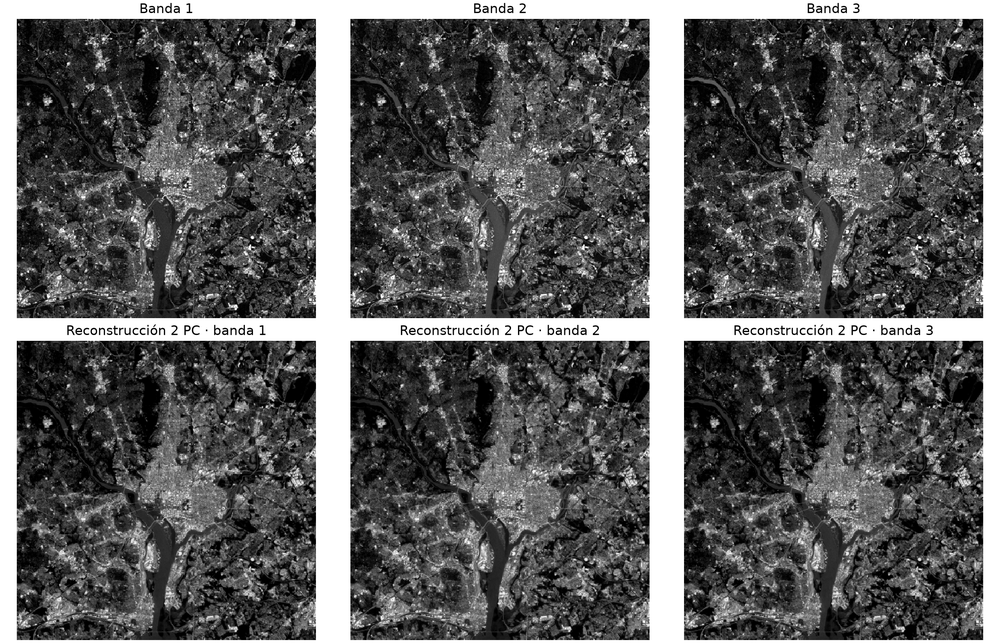

In [3]:
def show_preview(name, width=1000):
    im = Image.open(FIG / name)
    height = round(im.height * width / im.width)
    display(im.resize((width, height), Image.Resampling.LANCZOS))
show_preview("washington_bandas_pca2.png")


La reconstruccion retiene dos coordenadas espectrales por pixel. El factor ideal de reduccion es 6/2=3 si se cuentan solo los puntajes; almacenar media y base agrega un costo fijo pequeno frente a los 564x564 pixeles. El error se mide en el cubo completo, no solo en la visualizacion RGB.

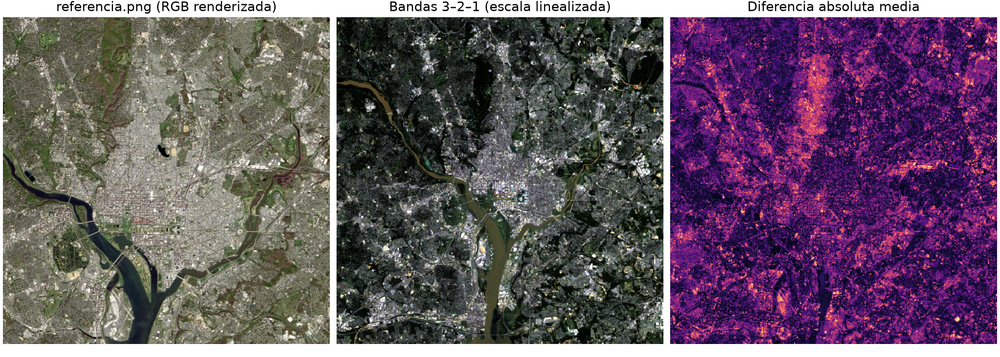

In [4]:
show_preview("referencia_vs_bandas.png")


`referencia.png` es una representacion RGB renderizada de Washington D. C., mientras las TIFF son medidas monocromaticas por banda. La comparacion 3-2-1 es visual; no se calcula PSNR/SSIM/SAM entre ambas porque no son imagenes registradas y radiometricamente equivalentes.

## 3. Segunda etapa: diez imagenes Tokio

El conjunto contiene 15 JPEG de 500x500 pixeles, codificados como RGB sRGB. Se elige una imagen de cada tipo: Butterfly base y las nueve escenas restantes. Se omiten Butterfly2-6 para evitar sobrerrepresentar esa serie. En estos datos las tres variables PCA son canales RGB, no bandas espectrales fisicas calibradas.

In [5]:
tokio = run_tokio()
print("Images:", tokio["selected_files"])
print("Selection rule:", tokio["selection_rule"])
display(pd.DataFrame([{"Image":r["image"], **{f"variance PC{i+1} (%)":100*v for i,v in enumerate(r["explained_variance_ratio"])} } for r in tokio["per_image"]]).round(3))

Images: ['Butterfly_sRGB.jpg', 'CD_sRGB.jpg', 'Character_sRGB.jpg', 'Cloth_sRGB.jpg', 'Cloth2_sRGB.jpg', 'Color_sRGB.jpg', 'Colorchart_sRGB.jpg', 'Fan_sRGB.jpg', 'Party_sRGB.jpg', 'Tshirts_sRGB.jpg']
Selection rule: Una imagen por tipo/escena: se incluye Butterfly_sRGB y se dejan fuera Butterfly2–6 para evitar sobrerrepresentar esa serie.


,Image,variance PC1 (%),variance PC2 (%),variance PC3 (%)
0,Butterfly_sRGB.jpg,76.181,21.642,2.177
1,CD_sRGB.jpg,64.051,25.450,10.499
2,Character_sRGB.jpg,92.409,4.996,2.595
3,Cloth_sRGB.jpg,90.384,7.908,1.708
4,Cloth2_sRGB.jpg,80.238,18.512,1.250
5,Color_sRGB.jpg,63.119,27.844,9.037
6,Colorchart_sRGB.jpg,58.430,28.581,12.988
7,Fan_sRGB.jpg,90.854,6.699,2.447
8,Party_sRGB.jpg,78.919,15.792,5.289
9,Tshirts_sRGB.jpg,97.864,1.445,0.691


### Metricas y criterio explicito para 90 %

PSNR esta expresado en decibelios y no admite una interpretacion lineal de porcentaje. Definimos **90 % de recuperacion** como al menos el 90 % de la mejora entre la reconstruccion de un componente y el rango completo:

- MSE: $(MSE_1-MSE_k)/(MSE_1-MSE_3)$;
- SSIM: $(SSIM_k-SSIM_1)/(SSIM_3-SSIM_1)$;
- SAM: $(SAM_1-SAM_k)/(SAM_1-SAM_3)$.

Se promedian las fracciones entre las diez imagenes y se requiere que las tres medias sean al menos 0.90. MSE se usa para el avance de PSNR porque PSNR es una transformacion logaritmica de MSE. Se muestran tambien las metricas brutas. SAM es el angulo medio entre vectores RGB de norma no nula; se excluyen pixeles donde la norma de alguno es cero porque alli el angulo no esta definido. Menor SAM es mejor.

In [6]:
means = tokio["mean_metrics"]
display(pd.DataFrame([{"PC":k, "MSE":v["mse"], "PSNR (dB)":v["psnr_db"], "SSIM":v["ssim"], "SAM (degrees)":v["sam_deg"]} for k,v in means.items()]).set_index("PC").round(5))
print("Mean recovery fractions:")
display(pd.DataFrame(tokio["recovery_progress"]).T.round(4))
print("Minimum components meeting at least 90 percent for all three fractions:", tokio["components_for_90_percent"])

,MSE,PSNR (dB),SSIM,SAM (degrees)
PC,,,,
1,0.00873,22.51898,0.89442,8.87079
2,0.00219,29.30875,0.96328,3.88529
3,0.00000,146.35944,1.00000,0.00000


Mean recovery fractions:


,mse_reduction_fraction,ssim_gain_fraction,sam_reduction_fraction
1,0.0000,0.0000,0.0000
2,0.7645,0.6693,0.5764
3,1.0000,1.0000,1.0000


Minimum components meeting at least 90 percent for all three fractions: 3


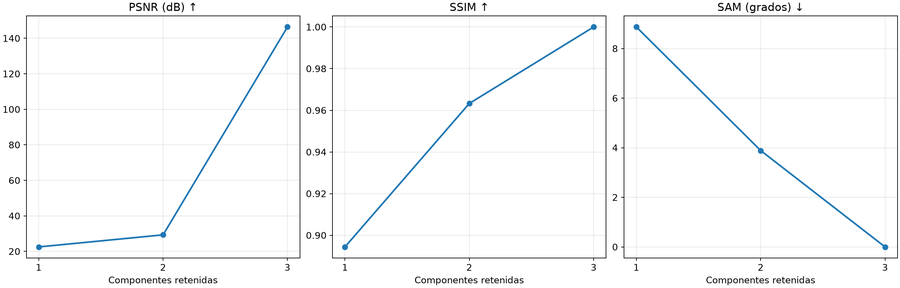

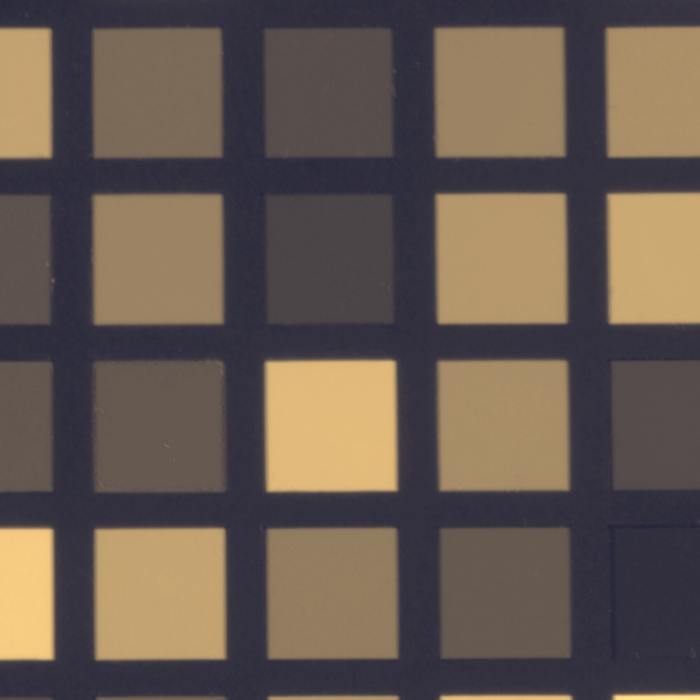

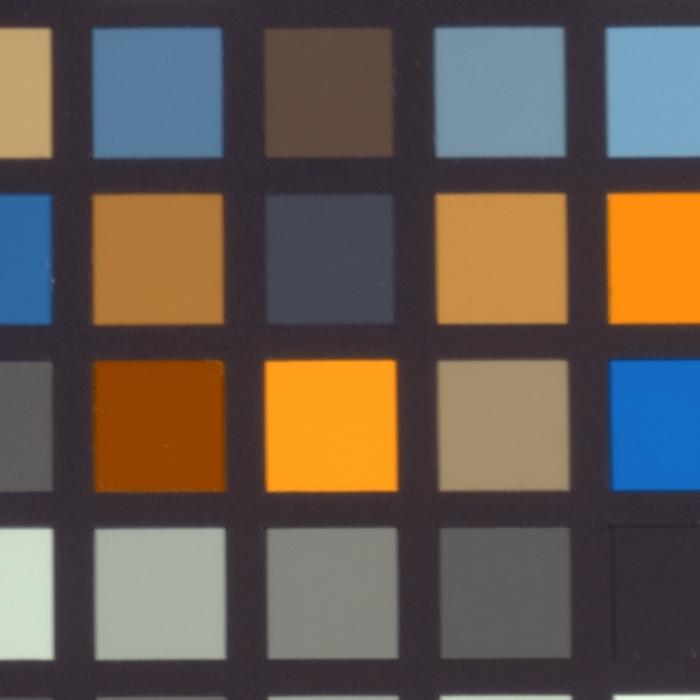

In [7]:
show_preview("metricas_tokio_pca.png", 900)
show_preview("colorchart_pca1.png", 700)
show_preview("colorchart_pca2.png", 700)


En RGB, tres componentes reproducen los tres canales y dan una reconstruccion numericamente exacta (PSNR muy alto por la precision de punto flotante). Es la referencia de rango completo, pero no reduce el numero de valores por pixel. Dos componentes son el caso de compresion: reduccion ideal 3:2 en puntajes frente a RGB, mas media y base compartidas por imagen. Bajo el criterio conjunto de 90 % se informa el minimo que realmente lo satisface, aunque resulte ser el rango completo.

## 4. Reproducibilidad y referencias

- Enunciado: `homework5.pdf`, *Principal Component Analysis for Multispectral Compression*, ecuaciones (1)-(5) y ejercicios 1-5.
- Material del profesor: `extra/material_curso/homework4/DIP3E_CH11_Original_Images/`, seis bandas TIFF Washington D. C.; `referencia.png` se usa como guia visual.
- `extra/material_curso/README.md` no incluye una guia de homework5.
- Notebook oficial: `extra/material_oficial/Chapter10SamplingStrategy/PrincipalComponentsOfImages.ipynb` (PCA, proyeccion y distorsion) y `multiSpectralImages.ipynb` (firmas espectrales por pixel y PCA); el README indica las secciones 10.2-10.3.
- El libro local es David J. Brady, *Computational Imaging*, capitulo 4, seccion de imagenes espectrales. El enunciado solicita *Digital Image Processing*, pp. 861-867; ese libro no esta en `files/`, asi que esta verificacion queda pendiente. No se atribuye a Brady el contenido del libro DIP.

El script `homework5.py` contiene el analisis y `resultados/resultados_pca.json` conserva las cifras completas. El notebook imprime el dispositivo realmente seleccionado.